In [2]:
import numpy as np

BASE = "/home/elicanter/bert_grn_out_61_masking/run0"

all_weights = np.load(f"{BASE}/mix_weights.npy")
print(all_weights.shape)

A_dict = np.load(f"{BASE}/A_dict.npy")
print(A_dict.shape)

initial_clusters = np.load(f"{BASE}/cluster_labels.npy")
print(initial_clusters.shape)

decipher_embeddings = np.load("/home/elicanter/datasets/hematopoiesis/decipher_embeddings.npz")
V_dec2 = decipher_embeddings["v"].astype(np.float32) 
print(V_dec2.shape)

A_genes = np.load(f"{BASE}/A_genes.npy")
A_tfs = np.load(f"{BASE}/A_tfs.npy")

(1035, 4)
(4, 11483, 277)
(1035,)
(1035, 2)


In [2]:
w_mean = all_weights.mean(axis=0)   # (D,)

A_learned = np.tensordot(w_mean, A_dict, axes=(0,0))  # (G, T)
print(A_learned.shape)

(11483, 277)


Atom usage stats (should NOT all be equal):
  Mean mixing weights per atom: [0.121 0.058 0.494 0.327]
  Std  mixing weights per atom: [0.126 0.09  0.175 0.217]
  Mean entropy: 0.922 / 1.39 max


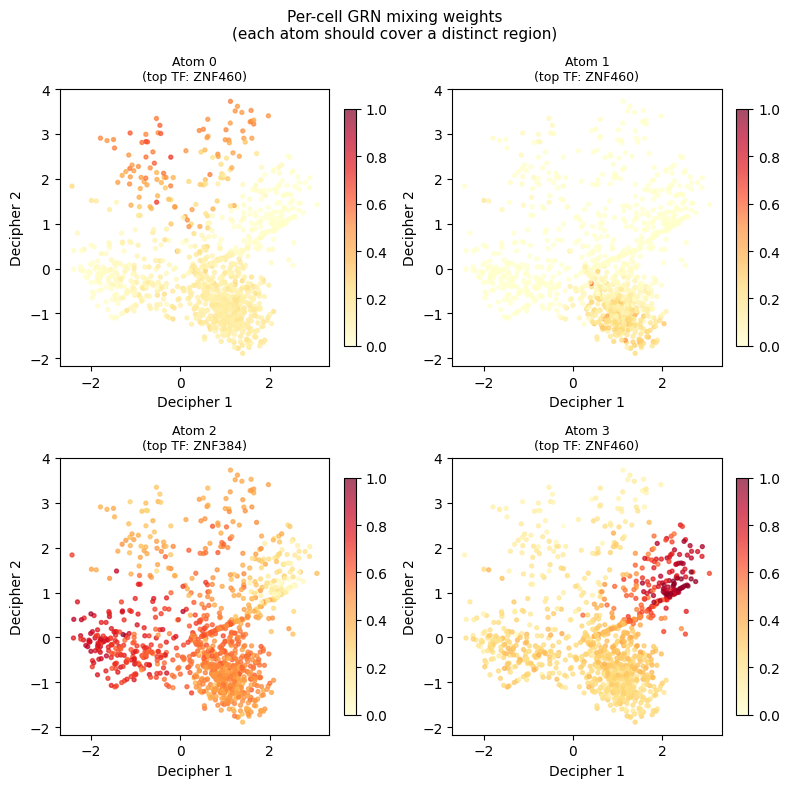

In [3]:
import matplotlib.pyplot as plt

D_ATOMS = all_weights.shape[1]
 
# Check: are atoms actually different?
print("Atom usage stats (should NOT all be equal):")
print("  Mean mixing weights per atom:", all_weights.mean(axis=0).round(3))
print("  Std  mixing weights per atom:", all_weights.std(axis=0).round(3))
print("  Mean entropy:", -(all_weights * np.log(all_weights + 1e-8)).sum(axis=1).mean().round(3),
      f"/ {np.log(D_ATOMS):.2f} max")
 
fig, axes = plt.subplots(2, D_ATOMS // 2, figsize=(4 * D_ATOMS // 2, 8))
axes = axes.flatten()
 
for d in range(D_ATOMS):
    ax = axes[d]
    sc = ax.scatter(V_dec2[:, 0], V_dec2[:, 1],
                    c=all_weights[:, d], cmap='YlOrRd',
                    s=8, alpha=0.7, vmin=0, vmax=1)
    plt.colorbar(sc, ax=ax, fraction=0.04)
    # Top TF for this atom
    A_atom = A_dict[d]  # (G, T)
    top_tf = A_tfs[np.abs(A_atom).sum(axis=0).argmax()]
    ax.set_title(f"Atom {d}\n(top TF: {top_tf})", fontsize=9)
    ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
 
plt.suptitle("Per-cell GRN mixing weights\n(each atom should cover a distinct region)",
             fontsize=11)
plt.tight_layout()
#plt.savefig("bert_grn_out_61/atom_weights_spatial.png", dpi=150, bbox_inches='tight')
plt.show()
#print("Saved: bert_grn_out_61/atom_weights_spatial.png")

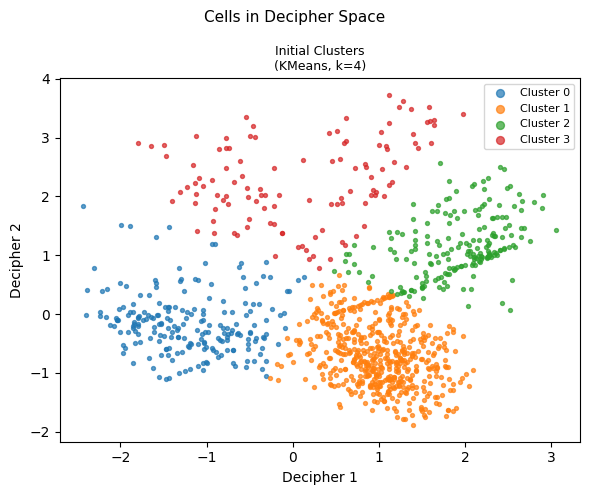

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

for cluster_id in range(4):
    mask = initial_clusters == cluster_id
    ax.scatter(V_dec2[mask, 0], V_dec2[mask, 1],
               c=colors[cluster_id], label=f'Cluster {cluster_id}',
               s=8, alpha=0.7)

ax.set_xlabel("Decipher 1"); ax.set_ylabel("Decipher 2")
ax.set_title("Initial Clusters\n(KMeans, k=4)", fontsize=9)
ax.legend(markerscale=2, fontsize=8)

plt.suptitle("Cells in Decipher Space", fontsize=11)
plt.tight_layout()

In [21]:
# ============================================================
# IMPROVED GRN COMPARISON: Your model vs CellOracle
# ============================================================

import numpy as np
import json
from scipy.stats import spearmanr, kendalltau
from scipy.optimize import linear_sum_assignment
import warnings

BASE = "/home/elicanter/"
#A_learned = np.load("bert_grn_out_61/A_learned.npy")   # <-- UPDATED NAME

# ------------------------------------------------------------------
# 0. Load CellOracle GRN
# ------------------------------------------------------------------
co_A     = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_genes.npy",
                   allow_pickle=True).astype(str)
co_tfs   = np.load(f"{BASE}/cell_oracle_run/cell_oracle_global_A/A_tfs.npy",
                   allow_pickle=True).astype(str)

print(f"co_A shape: {co_A.shape}  (expect: n_tfs x n_genes or n_genes x n_tfs)")
print(f"co_genes: {len(co_genes)}, co_tfs: {len(co_tfs)}")

# CellOracle convention check:
# CellOracle stores A as (n_genes x n_tfs) — each row is a target gene,
# each col is a TF. Confirm with shape:
if co_A.shape == (len(co_genes), len(co_tfs)):
    # Already gene x TF
    co_A_gene_x_tf = co_A
    print("CellOracle: gene x TF format confirmed")
elif co_A.shape == (len(co_tfs), len(co_genes)):
    # TF x gene — transpose
    co_A_gene_x_tf = co_A.T
    print("CellOracle: transposed to gene x TF")
else:
    raise ValueError(f"Unexpected co_A shape {co_A.shape} for "
                     f"{len(co_genes)} genes and {len(co_tfs)} TFs")

# ------------------------------------------------------------------
# 1. Align to shared gene x TF subspace
# ------------------------------------------------------------------
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs   = sorted(set(A_tfs)   & set(co_tfs))

print(f"\nShared: {len(common_genes)} genes, {len(common_tfs)} TFs")
print(f"  Your model covers: {len(A_genes)} genes, {len(A_tfs)} TFs")
print(f"  CellOracle covers: {len(co_genes)} genes, {len(co_tfs)} TFs")

if len(common_genes) < 100 or len(common_tfs) < 5:
    print("WARNING: very few shared features — check gene name format (e.g. ENSG vs symbol)")

# Index arrays
pred_g2i = {g: i for i, g in enumerate(A_genes)}
pred_t2i = {t: i for i, t in enumerate(A_tfs)}
co_g2i   = {g: i for i, g in enumerate(co_genes)}
co_t2i   = {t: i for i, t in enumerate(co_tfs)}

pred_g_idx = np.array([pred_g2i[g] for g in common_genes])
pred_t_idx = np.array([pred_t2i[t] for t in common_tfs])
co_g_idx   = np.array([co_g2i[g]   for g in common_genes])
co_t_idx   = np.array([co_t2i[t]   for t in common_tfs])

# Both in gene x TF format, restricted to shared subspace
A_pred_shared = A_learned[np.ix_(pred_g_idx, pred_t_idx)]   # (G_shared, T_shared)
A_co_shared   = co_A_gene_x_tf[np.ix_(co_g_idx, co_t_idx)]   # (G_shared, T_shared)

print(f"\nAligned matrices: pred={A_pred_shared.shape}, co={A_co_shared.shape}")

# ------------------------------------------------------------------
# 2. Normalize each matrix independently (important!)
#    Both to comparable scale before any comparison.
#    We use absolute value + column-wise rank normalization.
# ------------------------------------------------------------------

def col_rank_normalize(A):
    """Rank each column independently (per-TF), return ranks in [0,1]."""
    G, T = A.shape
    A_ranked = np.zeros_like(A, dtype=np.float32)
    for t in range(T):
        col = A[:, t]
        ranks = col.argsort().argsort().astype(np.float32)
        A_ranked[:, t] = ranks / (G - 1 + 1e-8)
    return A_ranked

A_pred_ranked = col_rank_normalize(np.abs(A_pred_shared))
A_co_ranked   = col_rank_normalize(np.abs(A_co_shared))

# ------------------------------------------------------------------
# 3. Multi-level comparison metrics
# ------------------------------------------------------------------

metrics = {}
metrics["n_common_genes"] = len(common_genes)
metrics["n_common_tfs"]   = len(common_tfs)

# ---- 3a. Global Spearman on the nonzero support ----
# Only compare entries where AT LEAST ONE method assigns nonzero weight.
# This avoids inflating agreement via double-zeros.
nonzero_mask = (np.abs(A_pred_shared) > 0) | (np.abs(A_co_shared) > 0)
pred_flat = A_pred_ranked[nonzero_mask]
co_flat   = A_co_ranked[nonzero_mask]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    rho_global, p_global = spearmanr(pred_flat, co_flat)

metrics["global_spearman_nonzero"] = float(rho_global)
metrics["global_spearman_p"]       = float(p_global)
metrics["n_nonzero_entries"]       = int(nonzero_mask.sum())
print(f"\nGlobal Spearman (nonzero support): rho={rho_global:.4f}, p={p_global:.3e}")

# ---- 3b. Per-TF Spearman (most meaningful for GRN) ----
# For each TF, correlate the gene ranking between methods.
# This tells you: "do both methods agree on which genes this TF regulates?"
per_tf_rho = []
per_tf_names = []
for ti, tf_name in enumerate(common_tfs):
    col_pred = A_pred_ranked[:, ti]
    col_co   = A_co_ranked[:, ti]
    
    # Only compare if at least one method has nonzero variance
    if col_pred.std() < 1e-8 or col_co.std() < 1e-8:
        continue
    
    rho, _ = spearmanr(col_pred, col_co)
    per_tf_rho.append(rho)
    per_tf_names.append(tf_name)

per_tf_rho = np.array(per_tf_rho)
metrics["per_tf_spearman_mean"] = float(np.nanmean(per_tf_rho))
metrics["per_tf_spearman_std"]  = float(np.nanstd(per_tf_rho))
metrics["per_tf_spearman_frac_pos"] = float(np.mean(per_tf_rho > 0))

print(f"Per-TF Spearman: mean={metrics['per_tf_spearman_mean']:.4f} ± "
      f"{metrics['per_tf_spearman_std']:.4f}, "
      f"frac positive={metrics['per_tf_spearman_frac_pos']:.3f}")

# Top and bottom TFs
top_idx = np.argsort(-per_tf_rho)[:10]
bot_idx = np.argsort(per_tf_rho)[:5]
print("\nTop 10 best-matching TFs:")
for i in top_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")
print("Bottom 5 TFs (worst match):")
for i in bot_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")

# ---- 3c. Top-k edge overlap (Jaccard) at multiple thresholds ----
# For each TF, what fraction of its "top k target genes" are shared?
print("\nTop-k edge overlap (per-TF Jaccard):")
for frac in [0.05, 0.10, 0.20]:
    jaccards = []
    for ti in range(len(common_tfs)):
        col_pred = np.abs(A_pred_shared[:, ti])
        col_co   = np.abs(A_co_shared[:, ti])
        k = max(1, int(np.ceil(frac * len(common_genes))))
        
        top_pred = set(np.argpartition(col_pred, -k)[-k:].tolist())
        top_co   = set(np.argpartition(col_co,   -k)[-k:].tolist())
        
        inter = len(top_pred & top_co)
        union = len(top_pred | top_co)
        jaccards.append(inter / (union + 1e-8))
    
    mean_j = np.mean(jaccards)
    metrics[f"per_tf_jaccard_top{int(frac*100)}pct"] = float(mean_j)
    print(f"  top {int(frac*100)}%: mean Jaccard = {mean_j:.4f}")

# ---- 3d. Network-level hub agreement ----
# Do both methods agree on WHICH TFs are the most influential (high out-degree)?
hub_pred = np.abs(A_pred_shared).sum(axis=0)  # (T,) — total gene drive per TF
hub_co   = np.abs(A_co_shared).sum(axis=0)

hub_rho, _ = spearmanr(hub_pred, hub_co)
metrics["hub_tf_spearman"] = float(hub_rho)
print(f"\nHub TF agreement (Spearman on total influence): rho={hub_rho:.4f}")

# ---- 3e. Sign agreement (do methods agree on activation vs repression?) ----
# Only on entries where both methods are nonzero
both_nonzero = (np.abs(A_pred_shared) > 1e-6) & (np.abs(A_co_shared) > 1e-6)
if both_nonzero.sum() > 0:
    sign_agree = np.mean(
        np.sign(A_pred_shared[both_nonzero]) == np.sign(A_co_shared[both_nonzero])
    )
    metrics["sign_agreement"] = float(sign_agree)
    print(f"Sign agreement (activation/repression): {sign_agree:.4f}")
    print("(0.5 = random, 1.0 = perfect — CellOracle may not have signed edges)")
else:
    metrics["sign_agreement"] = None
    print("Sign agreement: no overlapping nonzero entries")

# ---- 3f. Module-level conservation ----
# Do both methods produce similar regulatory modules?
# (Uses NMF factorization to identify modules, then matches them)
from sklearn.decomposition import NMF

n_modules = min(10, len(common_tfs) - 1)

# Fit NMF on absolute value of each matrix
nmf = NMF(n_components=n_modules, random_state=42, max_iter=500)

A_pred_abs = np.abs(A_pred_shared) + 1e-8
A_co_abs   = np.abs(A_co_shared)   + 1e-8

W_pred = nmf.fit_transform(A_pred_abs)    # (G, K)
H_pred = nmf.components_                  # (K, T)

nmf2   = NMF(n_components=n_modules, random_state=42, max_iter=500)
W_co   = nmf2.fit_transform(A_co_abs)
H_co   = nmf2.components_

pred_modules = module_sets_from_nmf(W_pred, H_pred)
co_modules   = module_sets_from_nmf(W_co,   H_co)

mod_result = match_module_sets(pred_modules, co_modules)
metrics["module_conservation_mean"] = float(mod_result["mean_conservation"])
metrics["module_conservation_std"]  = float(mod_result["std_conservation"])

print(f"\nModule conservation: mean={mod_result['mean_conservation']:.4f} ± "
      f"{mod_result['std_conservation']:.4f}")

# ------------------------------------------------------------------
# 4. Summary printout
# ------------------------------------------------------------------
print("\n" + "="*60)
print("SUMMARY: GRN comparison vs CellOracle")
print("="*60)
for k_m, v_m in metrics.items():
    if isinstance(v_m, float):
        print(f"  {k_m:45s}: {v_m:.4f}")
    else:
        print(f"  {k_m:45s}: {v_m}")

# ------------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------------
with open("uv_leading_metrics_improved/celloracle_overlap_metrics_v2.json", "w") as f:
    json.dump({k: (v if not isinstance(v, np.floating) else float(v))
               for k, v in metrics.items()}, f, indent=2)

# Save per-TF breakdown as CSV for your mentor
import pandas as pd
tf_df = pd.DataFrame({
    "tf": per_tf_names,
    "per_tf_spearman": per_tf_rho,
    "hub_pred": hub_pred[[list(common_tfs).index(t) for t in per_tf_names]],
    "hub_co":   hub_co[[list(common_tfs).index(t) for t in per_tf_names]],
})
tf_df = tf_df.sort_values("per_tf_spearman", ascending=False)
tf_df.to_csv("uv_leading_fixed/per_tf_grn_comparison.csv", index=False)
print("\nSaved: celloracle_overlap_metrics_v2.json, per_tf_grn_comparison.csv")

co_A shape: (277, 2995)  (expect: n_tfs x n_genes or n_genes x n_tfs)
co_genes: 2995, co_tfs: 277
CellOracle: transposed to gene x TF

Shared: 2995 genes, 277 TFs
  Your model covers: 11483 genes, 277 TFs
  CellOracle covers: 2995 genes, 277 TFs

Aligned matrices: pred=(2995, 277), co=(2995, 277)

Global Spearman (nonzero support): rho=0.5482, p=0.000e+00
Per-TF Spearman: mean=0.9218 ± 0.0749, frac positive=1.000

Top 10 best-matching TFs:
  ZBED1                 rho=1.000
  HOXA9                 rho=1.000
  MYBL2                 rho=1.000
  E2F1                  rho=1.000
  E2F4                  rho=1.000
  SMAD5                 rho=1.000
  CENPB                 rho=1.000
  E2F2                  rho=0.999
  GMEB2                 rho=0.999
  IRF6                  rho=0.999
Bottom 5 TFs (worst match):
  KLF5                  rho=0.615
  KLF4                  rho=0.649
  ZNF460                rho=0.666
  KLF2                  rho=0.712
  SPI1                  rho=0.741

Top-k edge overla

NameError: name 'module_sets_from_nmf' is not defined

In [8]:
import numpy as np
from scipy.stats import spearmanr

BASE = "/home/elicanter/bert_grn_out_61_masking2"
N_RUNS = 5

# ------------------------------------------------------------------
# 1. Load all runs and compute A_learned per run
# ------------------------------------------------------------------
A_runs = []

for r in range(N_RUNS):
    all_weights = np.load(f"{BASE}/run{r}/mix_weights.npy")   # (cells, D)
    A_dict      = np.load(f"{BASE}/run{r}/A_dict.npy")        # (D, G, T)
    
    w_mean    = all_weights.mean(axis=0)                       # (D,)
    A_learned = np.tensordot(w_mean, A_dict, axes=(0, 0))     # (G, T)
    A_runs.append(A_learned)

A_runs = np.stack(A_runs)   # (5, G, T)
print(f"Loaded {N_RUNS} runs, A shape per run: {A_runs[0].shape}")

# ------------------------------------------------------------------
# 2. Cross-run reproducibility: pairwise Spearman of flattened A_learned
# ------------------------------------------------------------------
print("\n--- Cross-run reproducibility (Spearman of flattened A_learned) ---")
rhos = np.ones((N_RUNS, N_RUNS))
for i in range(N_RUNS):
    for j in range(i+1, N_RUNS):
        rho, _ = spearmanr(A_runs[i].ravel(), A_runs[j].ravel())
        rhos[i, j] = rhos[j, i] = rho

for i in range(N_RUNS):
    for j in range(i+1, N_RUNS):
        print(f"  run{i} vs run{j}: rho={rhos[i,j]:.4f}")

off_diag = rhos[np.triu_indices(N_RUNS, k=1)]
print(f"  Mean pairwise rho: {off_diag.mean():.4f} ± {off_diag.std():.4f}")

# ------------------------------------------------------------------
# 3. CellOracle comparison on the mean A_learned across runs
# ------------------------------------------------------------------
A_mean = A_runs.mean(axis=0)   # (G, T) — average over runs for stable estimate

# Load CellOracle
co_A     = np.load(f"{BASE}/../cell_oracle_run/cell_oracle_global_A/A_celloracle.npy")
co_genes = np.load(f"{BASE}/../cell_oracle_run/cell_oracle_global_A/A_genes.npy", allow_pickle=True).astype(str)
co_tfs   = np.load(f"{BASE}/../cell_oracle_run/cell_oracle_global_A/A_tfs.npy",   allow_pickle=True).astype(str)

co_A_gene_x_tf = co_A if co_A.shape == (len(co_genes), len(co_tfs)) else co_A.T

# Align to shared subspace
common_genes = sorted(set(A_genes) & set(co_genes))
common_tfs   = sorted(set(A_tfs)   & set(co_tfs))
print(f"\nShared: {len(common_genes)} genes, {len(common_tfs)} TFs")

pred_g_idx = np.array([list(A_genes).index(g) for g in common_genes])
pred_t_idx = np.array([list(A_tfs).index(t)   for t in common_tfs])
co_g_idx   = np.array([list(co_genes).index(g) for g in common_genes])
co_t_idx   = np.array([list(co_tfs).index(t)   for t in common_tfs])

A_pred_shared = A_mean[np.ix_(pred_g_idx, pred_t_idx)]
A_co_shared   = co_A_gene_x_tf[np.ix_(co_g_idx, co_t_idx)]

# Metric 1: Hub TF agreement — which TFs are most globally influential?
print("\n--- CellOracle comparison ---")
hub_pred = np.abs(A_pred_shared).sum(axis=0)
hub_co   = np.abs(A_co_shared).sum(axis=0)
hub_rho, _ = spearmanr(hub_pred, hub_co)
print(f"Hub TF agreement (Spearman): rho={hub_rho:.4f}")

# Metric 2: Per-TF Spearman — do both methods agree on each TF's target genes?
per_tf_rho = []
for ti in range(len(common_tfs)):
    col_pred = np.abs(A_pred_shared[:, ti])
    col_co   = np.abs(A_co_shared[:, ti])
    if col_pred.std() < 1e-8 or col_co.std() < 1e-8:
        continue
    rho, _ = spearmanr(col_pred, col_co)
    per_tf_rho.append(rho)

per_tf_rho = np.array(per_tf_rho)
print(f"Per-TF Spearman: mean={per_tf_rho.mean():.4f} ± {per_tf_rho.std():.4f}")
print(f"  (note: inflated by shared sparsity — hub agreement is the cleaner metric)")

# ------------------------------------------------------------------
# 4. Summary
# ------------------------------------------------------------------
print("\n" + "="*50)
print("SUMMARY")
print("="*50)
print(f"  Cross-run reproducibility (mean rho): {off_diag.mean():.4f}")
print(f"  Hub TF agreement vs CellOracle:       {hub_rho:.4f}")
print(f"  Per-TF Spearman vs CellOracle:        {per_tf_rho.mean():.4f}")
print()
print("Interpretation guide:")
print("  Cross-run rho > 0.95  → model is stable")
print("  Hub rho       > 0.80  → top regulators match literature-backed GRN")
print("  Per-TF rho    > 0.70  → gene target rankings broadly agree")

Loaded 5 runs, A shape per run: (11483, 277)

--- Cross-run reproducibility (Spearman of flattened A_learned) ---
  run0 vs run1: rho=0.9197
  run0 vs run2: rho=0.9329
  run0 vs run3: rho=0.9177
  run0 vs run4: rho=0.9383
  run1 vs run2: rho=0.9219
  run1 vs run3: rho=0.9387
  run1 vs run4: rho=0.9226
  run2 vs run3: rho=0.9147
  run2 vs run4: rho=0.9390
  run3 vs run4: rho=0.9197
  Mean pairwise rho: 0.9265 ± 0.0091

Shared: 2995 genes, 277 TFs

--- CellOracle comparison ---
Hub TF agreement (Spearman): rho=0.8808
Per-TF Spearman: mean=0.9516 ± 0.0587
  (note: inflated by shared sparsity — hub agreement is the cleaner metric)

SUMMARY
  Cross-run reproducibility (mean rho): 0.9265
  Hub TF agreement vs CellOracle:       0.8808
  Per-TF Spearman vs CellOracle:        0.9516

Interpretation guide:
  Cross-run rho > 0.95  → model is stable
  Hub rho       > 0.80  → top regulators match literature-backed GRN
  Per-TF rho    > 0.70  → gene target rankings broadly agree


Worst 5 TFs by per-TF Spearman:


NameError: name 'per_tf_names' is not defined

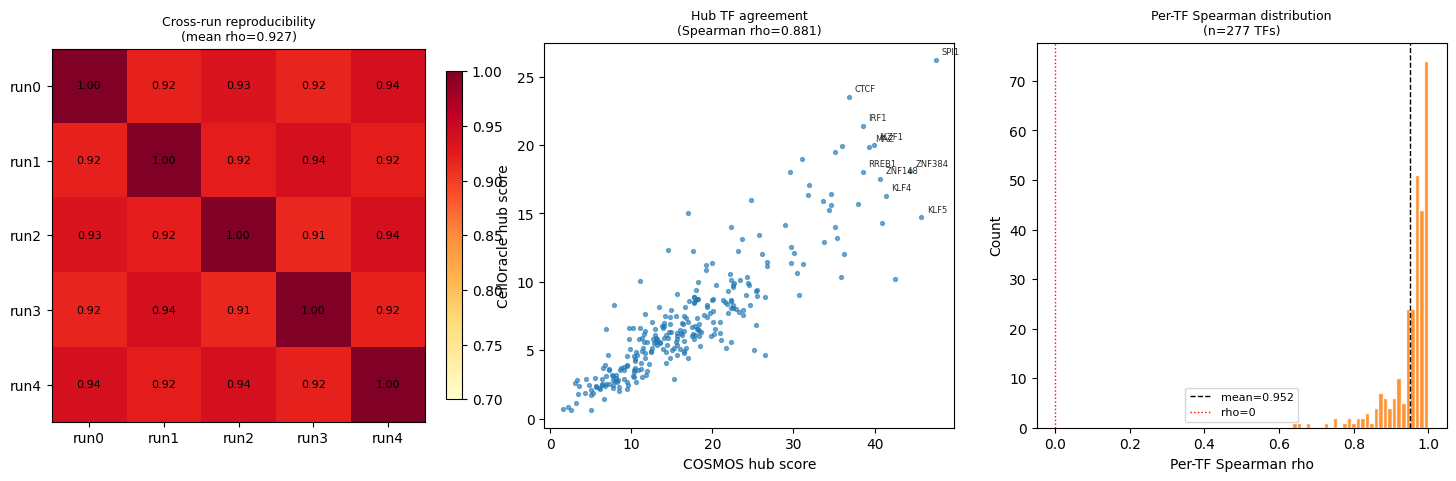

In [9]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ------------------------------------------------------------------
# 1. Pairwise reproducibility heatmap
# ------------------------------------------------------------------
ax = axes[0]
im = ax.imshow(rhos, cmap='YlOrRd', vmin=0.7, vmax=1.0)
plt.colorbar(im, ax=ax, fraction=0.04)
ax.set_xticks(range(N_RUNS)); ax.set_yticks(range(N_RUNS))
ax.set_xticklabels([f"run{r}" for r in range(N_RUNS)])
ax.set_yticklabels([f"run{r}" for r in range(N_RUNS)])
for i in range(N_RUNS):
    for j in range(N_RUNS):
        ax.text(j, i, f"{rhos[i,j]:.2f}", ha='center', va='center', fontsize=8)
ax.set_title(f"Cross-run reproducibility\n(mean rho={off_diag.mean():.3f})", fontsize=9)

# ------------------------------------------------------------------
# 2. Hub TF scatter: your model vs CellOracle
# ------------------------------------------------------------------
ax = axes[1]
ax.scatter(hub_pred, hub_co, s=8, alpha=0.6, c='tab:blue')

# Label top 10 TFs by average hub score
top10_idx = np.argsort(hub_pred + hub_co)[-10:]
for ti in top10_idx:
    ax.annotate(common_tfs[ti], (hub_pred[ti], hub_co[ti]),
                fontsize=6, alpha=0.85,
                xytext=(4, 4), textcoords='offset points')

ax.set_xlabel("COSMOS hub score"); ax.set_ylabel("CellOracle hub score")
ax.set_title(f"Hub TF agreement\n(Spearman rho={hub_rho:.3f})", fontsize=9)

# ------------------------------------------------------------------
# 3. Per-TF Spearman distribution
# ------------------------------------------------------------------
ax = axes[2]
ax.hist(per_tf_rho, bins=30, color='tab:orange', edgecolor='white', alpha=0.85)
ax.axvline(per_tf_rho.mean(), color='black', linestyle='--', linewidth=1,
           label=f"mean={per_tf_rho.mean():.3f}")
ax.axvline(0.0, color='red', linestyle=':', linewidth=1, label="rho=0")
ax.set_xlabel("Per-TF Spearman rho"); ax.set_ylabel("Count")
ax.set_title(f"Per-TF Spearman distribution\n(n={len(per_tf_rho)} TFs)", fontsize=9)
ax.legend(fontsize=8)

# Label the worst TFs for inspection
worst_idx = np.argsort(per_tf_rho)[:5]
print("Worst 5 TFs by per-TF Spearman:")
for i in worst_idx:
    print(f"  {per_tf_names[i]:20s}  rho={per_tf_rho[i]:.3f}")

plt.suptitle("GRN quality metrics", fontsize=11)
plt.tight_layout()
#plt.savefig("grn_quality_metrics.png", dpi=300, bbox_inches='tight')
plt.show()

In [33]:
rho_global, p_global = spearmanr(A_pred_shared.ravel(), A_co_shared.ravel())
print(f"Global Spearman vs CellOracle: rho={rho_global:.4f}, p={p_global:.3e}")

Global Spearman vs CellOracle: rho=0.2039, p=0.000e+00
